# 04 · Delivery Performance → Customer Satisfaction

**Main question:** How much does late delivery hurt customer ratings and retention, and what should Olist do about it?

**Method**
1. Measure the size of the effect (dose-response by days of delay).
2. Test it statistically (Mann-Whitney U, chi-square, relative risk with 95% CI).
3. Rule out the obvious confounder: **geography** (remote states are both later *and* possibly harsher reviewers).
4. Link it to retention.
5. Quantify the business trade-off of the fix.

Population: delivered orders with a review, Jan 2017 – Aug 2018. *Late* = arrived on a calendar day after the promised date.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from ecom import viz
from ecom.db import query

viz.set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)

In [ ]:
d = query("""
    SELECT order_id, customer_state, is_late, delivery_delay_days, delivery_days,
           estimated_delivery_days, review_score, is_negative_review
    FROM marts.fact_orders
    WHERE is_delivered AND in_analysis_window AND review_score IS NOT NULL
""")
d["is_late"] = d["is_late"].astype(bool)
d["is_negative_review"] = d["is_negative_review"].astype(bool)
print(f"{len(d):,} orders · {d['is_late'].mean():.1%} late")

95,560 orders · 6.7% late


## 1. Dose-response: ratings fall off a cliff after the promised day

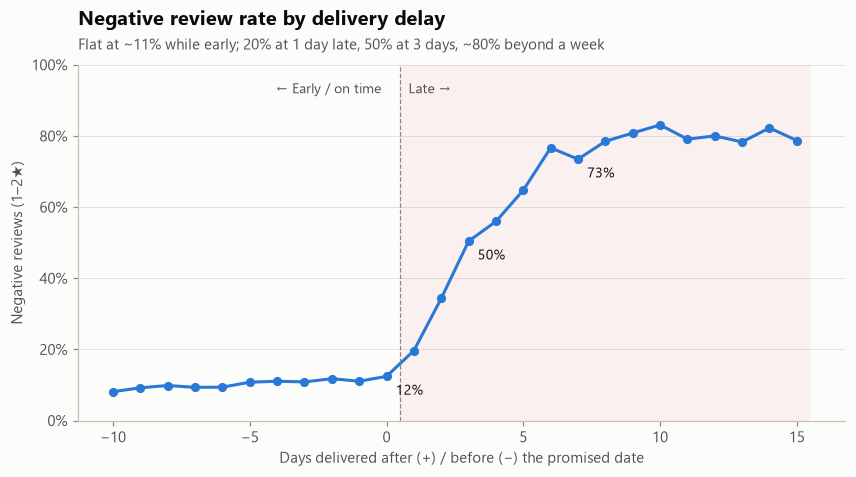

In [ ]:
curve = (
    d.query("delivery_delay_days.between(-10, 15)")
    .groupby("delivery_delay_days")["is_negative_review"]
    .agg(rate="mean", n="size")
)
curve["rate"] *= 100

fig, ax = plt.subplots()
ax.axvspan(0.5, 15.5, color=viz.CRITICAL, alpha=0.06, linewidth=0)
ax.plot(curve.index, curve["rate"], color=viz.BLUE, marker="o", markersize=5)
ax.axvline(0.5, color=viz.MUTED, linewidth=0.8, linestyle="--")
ax.text(0.8, 92, "Late →", color=viz.INK_2, fontsize=9)
ax.text(-0.2, 92, "← Early / on time", color=viz.INK_2, fontsize=9, ha="right")
for day in (0, 3, 7):
    r = curve.loc[day, "rate"]
    ax.annotate(
        f"{r:.0f}%",
        (day, r),
        xytext=(6, -12),
        textcoords="offset points",
        fontsize=9,
        color=viz.INK,
    )
ax.yaxis.set_major_formatter(viz.PCT)
ax.set_ylim(0, 100)
ax.set_xlabel("Days delivered after (+) / before (−) the promised date")
ax.set_ylabel("Negative reviews (1–2★)")
ax.set_title("Negative review rate by delivery delay")
viz.subtitle(ax, "Flat at ~11% while early; 20% at 1 day late, 50% at 3 days, ~80% beyond a week")
viz.save(fig, "delay_vs_negative_reviews")
plt.show()

Three things stand out:
- **Arriving early earns almost nothing.** Negative reviews sit at ~11% whether an order arrives 10 days early or 1 day early.
  Customers judge against the promise, not against absolute speed.
- **The penalty starts on day 1 and is steep:** it doubles in one day and passes 50% by day 3.
- The first 3 days of delay are the window where an intervention (a proactive apology, tracking update or voucher) can still change the outcome.

## 2. Is the effect statistically significant, and how big is it?

In [ ]:
late, ontime = d.loc[d["is_late"], "review_score"], d.loc[~d["is_late"], "review_score"]

mw = stats.mannwhitneyu(late, ontime, alternative="less")
rank_biserial = 1 - 2 * mw.statistic / (len(late) * len(ontime))

table_ = pd.crosstab(d["is_late"], d["is_negative_review"])
chi = stats.chi2_contingency(table_)

p1, n1 = d.loc[d["is_late"], "is_negative_review"].mean(), d["is_late"].sum()
p0, n0 = d.loc[~d["is_late"], "is_negative_review"].mean(), (~d["is_late"]).sum()
rr = p1 / p0
se_log_rr = np.sqrt((1 - p1) / (p1 * n1) + (1 - p0) / (p0 * n0))
rr_ci = np.exp(np.log(rr) + np.array([-1.96, 1.96]) * se_log_rr)

pd.Series(
    {
        "avg score: on time": ontime.mean(),
        "avg score: late": late.mean(),
        "Mann-Whitney U p-value (late < on time)": mw.pvalue,
        "effect size: rank-biserial r": rank_biserial,
        "negative-review rate: on time": p0,
        "negative-review rate: late": p1,
        "chi-square p-value": chi.pvalue,
        "relative risk (late vs on time)": rr,
        "relative risk 95% CI low": rr_ci[0],
        "relative risk 95% CI high": rr_ci[1],
    },
    name="value",
).to_frame()

,value
avg score: on time,4.29
avg score: late,2.27
Mann-Whitney U p-value (late < on time),0.00
effect size: rank-biserial r,0.64
negative-review rate: on time,0.09
negative-review rate: late,0.62
chi-square p-value,0.00
relative risk (late vs on time),6.75
relative risk 95% CI low,6.56
relative risk 95% CI high,6.94


- The difference is significant far beyond any conventional threshold (p ≈ 0, n ≈ 95K).
- More importantly, it is **large**: a rank-biserial r ≈ 0.64 is a large effect, and late orders are **~6.7× as likely**
  (95% CI shown above) to get a 1–2★ review: 62% vs 9%.

## 3. Is it really lateness, or just geography?
Remote states have longer, later deliveries. If their customers are simply harsher reviewers, the effect above would be confounded.
Compare late vs on-time **within the same state**:

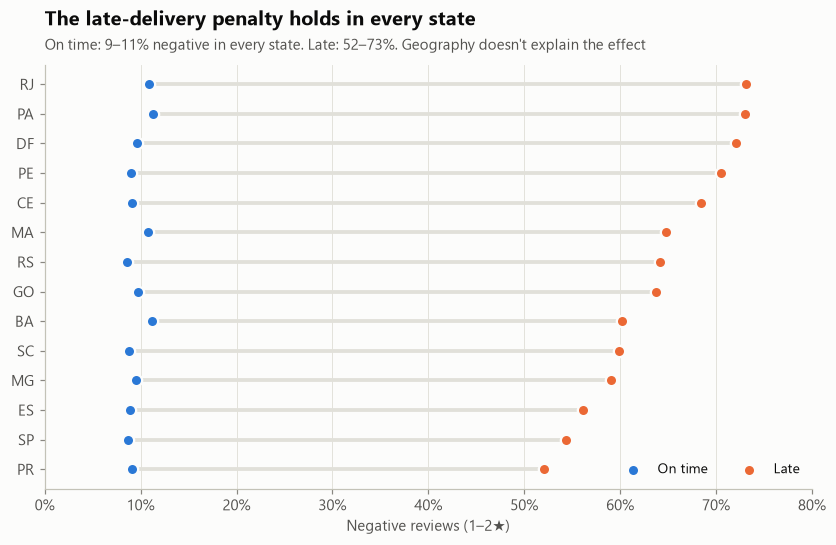

Crude relative risk: 6.75  |  State-adjusted (Mantel-Haenszel) relative risk: 6.52


In [ ]:
by_state = (
    d.groupby(["customer_state", "is_late"])["is_negative_review"].agg(["mean", "size"]).unstack()
)
by_state = by_state[by_state[("size", True)] >= 100]  # enough late orders for a stable rate
by_state = by_state.sort_values(("mean", True))
ontime_rate, late_rate = by_state[("mean", False)] * 100, by_state[("mean", True)] * 100

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(by_state))
ax.hlines(y, ontime_rate, late_rate, color=viz.GRID, linewidth=2.5)
ax.scatter(
    ontime_rate,
    y,
    color=viz.BLUE,
    s=55,
    zorder=3,
    label="On time",
    edgecolor=viz.SURFACE,
    linewidth=1.5,
)
ax.scatter(
    late_rate,
    y,
    color=viz.ORANGE,
    s=55,
    zorder=3,
    label="Late",
    edgecolor=viz.SURFACE,
    linewidth=1.5,
)
ax.set_yticks(y, by_state.index)
ax.xaxis.set_major_formatter(viz.PCT)
ax.set_xlim(0, 80)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Negative reviews (1–2★)")
ax.legend(loc="lower right", ncols=2)
ax.set_title("The late-delivery penalty holds in every state")
viz.subtitle(
    ax, "On time: 9–11% negative in every state. Late: 52–73%. Geography doesn't explain the effect"
)
viz.save(fig, "late_effect_by_state")
plt.show()

# Mantel-Haenszel pooled relative risk (stratified by state): the confounder-adjusted effect
s = d.groupby("customer_state").apply(
    lambda g: pd.Series(
        {
            "a": (g["is_late"] & g["is_negative_review"]).sum(),
            "n1": g["is_late"].sum(),
            "c": (~g["is_late"] & g["is_negative_review"]).sum(),
            "n0": (~g["is_late"]).sum(),
        }
    ),
    include_groups=False,
)
s["N"] = s["n1"] + s["n0"]
mh_rr = (s["a"] * s["n0"] / s["N"]).sum() / (s["c"] * s["n1"] / s["N"]).sum()
print(
    f"Crude relative risk: {rr:.2f}  |  State-adjusted (Mantel-Haenszel) relative risk: {mh_rr:.2f}"
)

The adjusted relative risk is essentially the same as the crude one, so **geography is not the explanation.** Lateness itself drives the bad reviews.

## 4. Does a late first order cost us the customer?

In [ ]:
first = query("""
    SELECT f.is_late, c.lifetime_orders > 1 AS repeated
    FROM marts.fact_orders f JOIN marts.dim_customer c USING (customer_unique_id)
    WHERE f.customer_order_seq = 1 AND f.is_delivered AND f.in_analysis_window
      AND f.purchase_date < DATE '2018-03-01'
""")
first["is_late"] = first["is_late"].astype(bool)
rep = first.groupby("is_late")["repeated"].agg(repeat_rate="mean", customers="size")
chi_rep = stats.chi2_contingency(pd.crosstab(first["is_late"], first["repeated"]))
rel_drop = 1 - rep.loc[True, "repeat_rate"] / rep.loc[False, "repeat_rate"]
print(f"Repeat rate after on-time first order: {rep.loc[False, 'repeat_rate']:.2%}")
print(
    f"Repeat rate after late first order:    {rep.loc[True, 'repeat_rate']:.2%}  "
    f"({rel_drop:.0%} lower, chi-square p = {chi_rep.pvalue:.4f})"
)

Repeat rate after on-time first order: 4.13%
Repeat rate after late first order:    3.06%  (26% lower, chi-square p = 0.0017)


A late first order cuts the (already tiny) repeat rate by about a quarter, and the result is statistically significant.
In absolute terms this is small, because retention is low for everyone (notebook 03). **The main cost of lateness is reputation**:
public 1–2★ reviews on a marketplace that lives on ratings.

## 5. The business trade-off: why not just promise later?
Olist already pads its promises heavily: on average it promises **~24 days** for a delivery that takes **~12.5**.
What happens if the promise is cut uniformly?

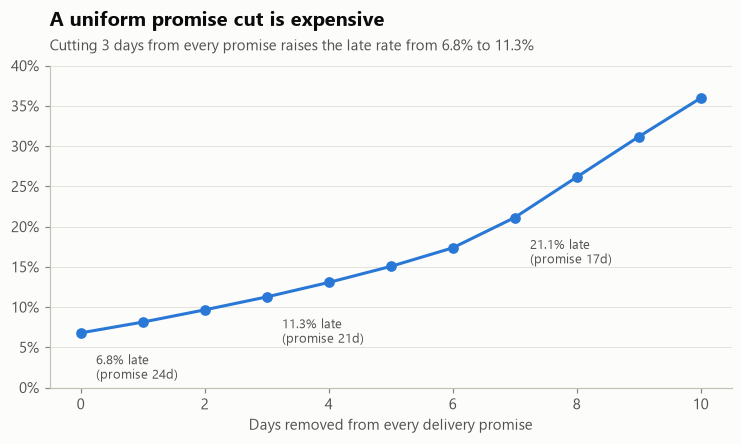

In [ ]:
o = query("""
    SELECT delivery_delay_days, estimated_delivery_days
    FROM marts.fact_orders WHERE is_delivered AND in_analysis_window
""")
sim = pd.DataFrame(
    {
        "days_cut_from_promise": range(0, 11),
    }
).assign(
    avg_promised_days=lambda x: [
        o["estimated_delivery_days"].mean() - k for k in x["days_cut_from_promise"]
    ],
    late_pct=lambda x: [
        ((o["delivery_delay_days"] + k) > 0).mean() * 100 for k in x["days_cut_from_promise"]
    ],
)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(sim["days_cut_from_promise"], sim["late_pct"], color=viz.BLUE, marker="o")
for k in (0, 3, 7):
    r = sim.loc[k]
    ax.annotate(
        f"{r['late_pct']:.1f}% late\n(promise {r['avg_promised_days']:.0f}d)",
        (k, r["late_pct"]),
        xytext=(10, -30),
        textcoords="offset points",
        fontsize=8.5,
        color=viz.INK_2,
    )
ax.yaxis.set_major_formatter(viz.PCT)
ax.set_ylim(0, 40)
ax.set_xlabel("Days removed from every delivery promise")
ax.set_title("A uniform promise cut is expensive")
viz.subtitle(ax, "Cutting 3 days from every promise raises the late rate from 6.8% to 11.3%")
viz.save(fig, "promise_tradeoff")
plt.show()

The padding is a deliberate safety buffer, and a blanket cut would backfire. The real opportunity is **route-level accuracy**:
promise short on predictable routes (same state; same-state orders average 7.9 days with 4.6% late) and long on risky ones
(cross-country; 15.2 days, 8.2% late). That needs a delivery-time prediction model, built in notebook 06.

## Impact estimate

In [ ]:
excess = n1 * (p1 - p0)
print(f"Late orders with a review:                         {n1:,}")
print(f"Extra negative reviews caused by lateness:         {excess:,.0f}")
print(
    f"Share of ALL negative reviews that are 'excess':   {excess / d['is_negative_review'].sum():.0%}"
)
print(f"If the late rate were halved: negative reviews avoided ≈ {excess / 2:,.0f}")

Late orders with a review:                         6,378
Extra negative reviews caused by lateness:         3,391
Share of ALL negative reviews that are 'excess':   28%
If the late rate were halved: negative reviews avoided ≈ 1,696


## Conclusions

1. **Lateness is the strongest driver of bad reviews found in this data.** Late orders are ~6.7× as likely to get 1–2★ (62% vs 9%),
   with a large effect size, and the result holds within every state.
2. **The promise is what counts, not the speed.** Early delivery earns no extra credit; even one day late doubles the negative-review rate.
3. Lateness causes roughly **3,400 excess negative reviews, ~28% of all negative reviews**, and lowers the repeat rate by ~25%.

## Recommendations

| # | Action | Expected effect | How to measure |
|---|---|---|---|
| 1 | **Predict delivery time per route** and set promises from it (notebook 06) | Shorter promises where safe, fewer late orders where risky | Late rate, promise length, conversion |
| 2 | **Day-0 alert:** when a parcel will miss its promise, notify the customer proactively with a small voucher | Catches customers before the day-1–3 cliff | Negative-review rate of late orders, A/B tested |
| 3 | **Peak-season playbook** (Nov, Feb–Mar): add capacity, temporarily lengthen risky routes | Avoids the 12–19% late spikes | Monthly late rate |
| 4 | **Seller SLAs** for high-volume sellers with high late rates (notebook 05) | Fixes the source | Seller late rate |